***
**Python Exercise** <br>
Exercise 2, Deadline: 29<sup>th</sup> Esfand, 19<sup>th</sup> March
***

# Exercise sheet: Supervised Regression

In [1]:
#| label: import
# Consider the following libraries for this exercise sheet:

# general
import numpy as np
import pandas as pd
import math
# plots
import matplotlib.pyplot as plt
import seaborn as sns
# sklearn
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
import sklearn.metrics as metrics
from sklearn.metrics import mean_absolute_error

## Exercise 1: HRO

We will frequently use the Python package `sklearn`, and its descendants, providing an integrated ecosystem for all common machine learning tasks. Let’s recap the HRO
principle and see how it is reflected in `sklearn`.<br>
An overview of the most important objects andtheir usage, illustrated with numerous examples, can be found at __[https://scikit-learn.org/stable/index.html](https://scikit-learn.org/stable/index.html)__.

> a) How are the key concepts (i.e., hypothesis space, risk and optimization) you learned about in the lecture videos
implemented?

The key concepts of Hypothesis Space, Risk, and Optimization are implemented in scikit-learn as follows:
### Hypothesis Space:
In scikit-learn, each machine learning algorithm represents a specific hypothesis space.
For example, LinearRegression represents linear models, DecisionTreeRegressor represents decision tree models.
The hypothesis space is defined by the model's parameters and the learning algorithm's structure.
### Risk:
Risk is typically represented by loss functions or metrics.
scikit-learn provides various loss functions in sklearn.metrics:
Mean Squared Error (MSE)
Mean Absolute Error (MAE)
R-squared score

The empirical risk is calculated during model training to guide parameter optimization.
### Optimization:
Optimization is handled internally by each algorithm's fitting method.
For linear regression, it uses techniques like ordinary least squares.
For decision trees, it uses recursive splitting to minimize impurity.
Gradient-based methods like in neural networks use backpropagation.

> b) Have a look at `sklearn.datasets import load_iris`. What attributes does this
object store?

In [2]:
# Enter your code here:
# Load the dataset
iris = load_iris()

# Print out the attributes
print("Data attributes:")
print(iris.keys())

# More detailed exploration
print("\nFeature names:")
print(iris.feature_names)

print("\nTarget names:")
print(iris.target_names)

print("\nData shape:")
print(iris.data.shape)

print("\nTarget shape:")
print(iris.target.shape)

Data attributes:
dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

Feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target names:
['setosa' 'versicolor' 'virginica']

Data shape:
(150, 4)

Target shape:
(150,)


> c) Instantiate a regression tree learner (`DecisionTreeRegressor`). What are the different settings for this learner?

<div class="alert alert-block alert-info">
<b>Hint:</b> Import the specific module and use <code>get_params()</code> to see all available settings.
</div>

In [3]:
# Enter your code here:
# Create a decision tree regressor
dt_regressor = DecisionTreeRegressor()

# Print all available parameters
print(dt_regressor.get_params())

{'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': None, 'splitter': 'best'}


The empirical risk is:

$$
\mathcal{R}_{emp}(\mathbf{\theta})= \sum_{i=1}^{50} \left( y^{(i)} - \left[ \theta_0 + \theta_1 x^{(i)} + \theta_2 \left(x^{(i)}\right)^2 + \theta_3 \left(x^{(i)}\right)^3 \right] \right)^2
$$

We can find the gradient just as we did for an intermediate result when we derived the least-squares estimator:
$$
\nabla_{\mathbf{\theta}} \mathcal{R}_{emp}(\mathbf{\theta}) = \frac{\partial}{\partial \mathbf{\theta}} \left \| \mathbf{y} - \mathbf{X}\mathbf{\theta} \right \|_2^2\\
= \frac{\partial}{\partial \mathbf{\theta}} \left( (\mathbf{y} - \mathbf{X}\mathbf{\theta})^\top (\mathbf{y} - \mathbf{X}\mathbf{\theta})\right)\\
= -2 \mathbf{y}^\top \mathbf{X}  + 2 \mathbf{\theta}^\top \mathbf{X}^\top \mathbf{X} \\
= 2 \cdot \left( -\mathbf{y}^\top \mathbf{X} + \mathbf{\theta}^\top \mathbf{X}^\top \mathbf{X} \right)
$$

Recall that the idea of gradient descent (*descent!*) is to traverse the risk surface in the direction of the negative
gradient as we are in search for the minimum. Therefore, we will update our current parameter set $\mathbf{\theta}^{[t]}$ with
the negative gradient of the current empirical risk w.r.t. $\mathbf{\theta}$, scaled by learning rate (or step size) $\alpha$:
$$
\mathbf{\theta}^{[t+1]} = \mathbf{\theta}^{[t]} - \alpha \cdot \nabla_{\mathbf{\theta}} \mathcal{R}_{emp}(\mathbf{\theta}^{[t]}) 
$$

What actually happens here: we update each component of our current parameter vector $\mathbf{\theta}^{[t]}$
in the *direction* of the negative gradient, i.e., following the steepest downward slope, and also by an *amount* that depends on the value of the gradient.


In order to see what that means it is helpful to recall that the gradient $\nabla_{\mathbf{\theta}} \mathcal{R}_{emp}(\mathbf{\theta})$ tells us about the effect (infinitesimally small) changes in $\mathbf{\theta}$ have on $\mathcal{R}_{emp}(\mathbf{\theta})$. A parameter vector component with large gradient has strong impact on the empirical risk, and it is reasonable to assume it to be rather important for the model. <br>
Therefore, gradient updates focus on influential components, and we proceed more quickly along the important
dimensions.

## Exercise 2: Predicting `abalone`

We want to predict the age of an abalone using its longest shell measurement and its weight. <br>
See __[https://archive.ics.uci.edu/ml/machine-learning-databases/abalone/](https://archive.ics.uci.edu/ml/machine-learning-databases/abalone/)__ for more details.

In [4]:
import pandas as pd
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/abalone/abalone.data"
abalone = pd.read_csv(url, sep=",",
names=["sex", "longest_shell", "diameter", "height", "whole_weight",
"shucked_weight", "visceral_weight", "shell_weight", "rings"])
abalone = abalone[["longest_shell", "whole_weight", "rings"]]

> a) Plot `LongestShell` and `WholeWeight` on the x- and y-axis, respectively, and color points according to `Rings`.

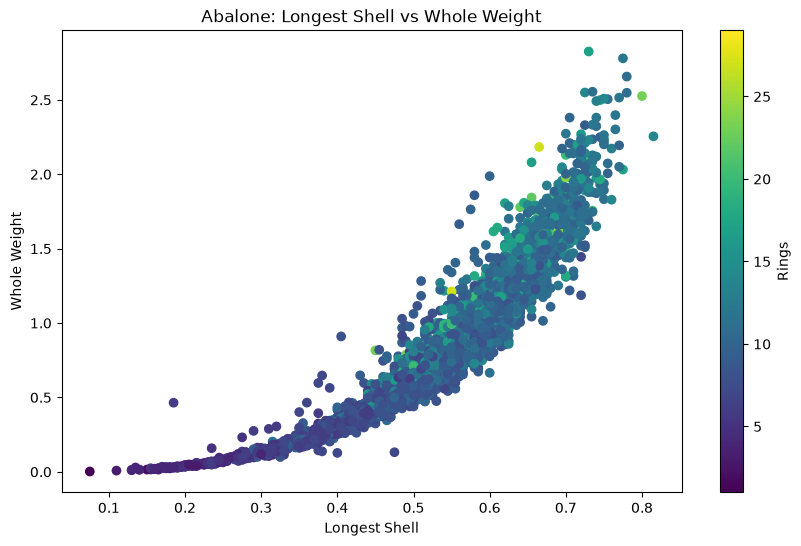

In [5]:
# Enter your code here:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(abalone['longest_shell'], abalone['whole_weight'], 
                      c=abalone['rings'], cmap='viridis')
plt.colorbar(scatter, label='Rings')
plt.xlabel('Longest Shell')
plt.ylabel('Whole Weight')
plt.title('Abalone: Longest Shell vs Whole Weight')
plt.show()

> b) Using `sklearn`, fit a linear regression model to the data.

In [6]:
# Enter your code here:
from sklearn.model_selection import train_test_split

# Prepare the features and target
X = abalone[['longest_shell', 'whole_weight']]
y = abalone['rings']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create and fit the linear regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Print model coefficients
print("Intercept:", lr_model.intercept_)
print("Coefficients:", lr_model.coef_)

Intercept: 3.5413515866328176
Coefficients: [10.3324298   1.17847379]


> c) Compare the fitted and observed targets visually.

<div class="alert alert-block alert-info">
<b>Python:</b> use <code>import matplotlib.pyplot as plt</code>. 
</div>

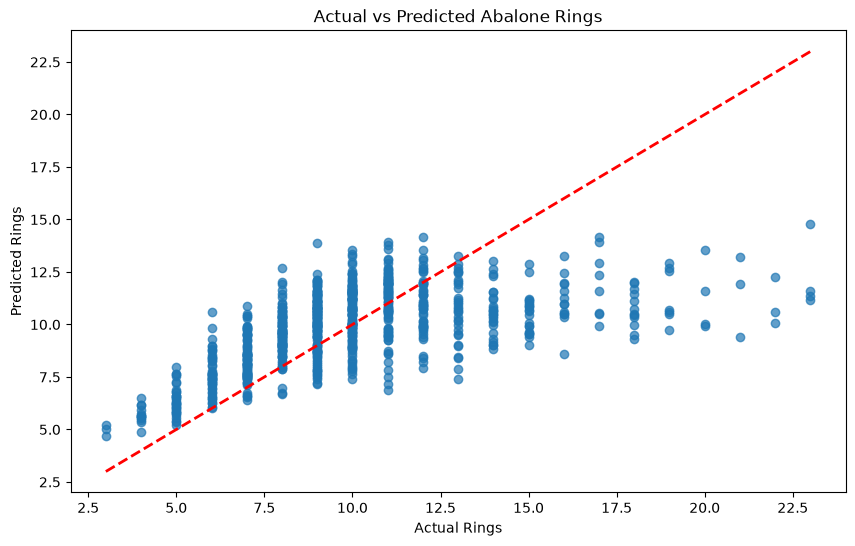

In [7]:
# Enter your code here:
# Predict on the test set
y_pred = lr_model.predict(X_test)

# Create a scatter plot of predicted vs actual values
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Rings')
plt.ylabel('Predicted Rings')
plt.title('Actual vs Predicted Abalone Rings')
plt.show()

> d) Assess the model’s training loss in terms of MAE.

<div class="alert alert-block alert-info">
<b>Python Hint:</b> The MAE metric is retrieved by calling <code>from sklearn.metrics import mean_absolute_error</code>.
</div>

In [8]:
# Enter your code here:
# Calculate Mean Absolute Error
mae = mean_absolute_error(y_test, y_pred)
print(f"Mean Absolute Error: {mae:.4f}")

Mean Absolute Error: 1.9524
